# 3조 · 건강보험 고객의 차량보험 관심 여부 예측
## 분류 프로젝트: 문제 정의 → EDA → 전처리 → 모델 비교 → 튜닝 → 평가 → 해석

**목표:** 기존 건강보험 고객이 차량보험에 관심을 보일지(`Response`) 예측한다.
`1`은 관심 있음, `0`은 관심 없음이다. 실제 가입·계약 체결이나 보험금 청구를 예측하는 문제가 아니다.
관심 가능성이 높은 고객부터 상품을 안내하는 데 참고할 수 있다.

이 노트북은 `Guidline.pdf`의 순서를 따르며, 수업 노트북의 분석 방법을 사용한다.
이전 대화의 모델·점수를 복사하지 않고 여기서 직접 다시 학습한다.
오버샘플링·언더샘플링·SMOTE·클래스 가중치는 사용하지 않는다. PPT는 만들지 않는다.

### 실행 방법과 수업 범위

1. `test2.ipynb`, `train.csv`, `test.csv`, `sample_submission.csv`를 같은 `project` 폴더에 둔다.
2. 현재 프로젝트의 `ML/.venv` Python 커널을 선택한다. 다른 환경은 `requirements.txt`를 설치한다.
3. **커널 다시 시작 → 모두 실행**한다. 전체 학습 데이터를 사용하므로 모델 비교·튜닝은 몇 분 이상 걸릴 수 있다.
4. 실험 로그와 제출용 예측은 `test2_outputs` 폴더에 저장된다. 재실행하면 이 노트북의 결과 파일을 갱신한다.

|내용|수업 근거|
|---|---|
|빈도·비율, 그룹 비교, 히스토그램, 박스플롯, 상관관계, IQR, 로그변환|`ML_Class/01.ipynb`|
|분할, 인코딩, 스케일링, 교차검증, GridSearchCV|`ch02/2_1.ipynb`|
|로지스틱 회귀·결정트리·랜덤포레스트|`ch02/2_2.ipynb`|
|오차행렬, Precision/Recall/F1, ROC-AUC, PR곡선, 임계값 비교|`ch03/3_1.ipynb`|
|랜덤포레스트 튜닝, XGBoost, LightGBM, 중요도|`ch04/4_2.ipynb` ~ `ch04/4_4.ipynb`|

`Pipeline`과 `ColumnTransformer`는 가이드라인 2-3에서 권장하는 연결 도구로만 사용한다.
수업의 인코더·스케일러가 **교차검증의 각 학습 fold 안에서만 fit**되게 묶는 역할이다.
새 알고리즘, SHAP, 스태킹, 자동 튜닝 도구는 추가하지 않는다.

In [1]:
from pathlib import Path
import sys
import json
import time
import hashlib
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

SEED = 42
N_SPLITS = 3
N_JOBS = 4
np.random.seed(SEED)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 100)
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 110

# project 폴더 또는 저장소 최상위에서 실행할 수 있다.
DATA_DIR = next((p for p in [Path.cwd(), Path.cwd() / 'project']
                 if (p / 'train.csv').is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError('project 폴더에서 실행하거나 CSV 파일 위치를 확인하세요.')
OUT_DIR = DATA_DIR / 'test2_outputs'
OUT_DIR.mkdir(exist_ok=True)

packages = ['numpy', 'pandas', 'scipy', 'matplotlib', 'seaborn',
            'scikit-learn', 'xgboost', 'lightgbm', 'ipykernel', 'nbformat', 'nbclient']
versions = {name: metadata.version(name) for name in packages}
print('Python:', sys.version.split()[0], '| seed:', SEED)
display(pd.Series(versions, name='version').to_frame())

Python: 3.10.22 | seed: 42


,version
numpy,1.23.5
pandas,1.5.3
scipy,1.9.3
matplotlib,3.6.3
seaborn,0.13.2
scikit-learn,1.0.2
xgboost,1.7.6
lightgbm,4.5.0
ipykernel,7.3.0
nbformat,5.11.1


## 1. 문제 정의와 성공 기준

**출처:** [Anmol Kumar · Health Insurance Cross Sell Prediction](https://www.kaggle.com/datasets/anmolkumar/health-insurance-cross-sell-prediction).
데이터 카드에 표시된 라이선스는 **GPL 2**이다(2026-10-15 확인).
로컬 CSV를 사용하며 재실행 시 외부 다운로드나 인증키는 필요하지 않다.

- **주 지표:** 데이터 카드의 평가 지표인 ROC-AUC. 확률의 순위 구분 능력을 측정한다.
- **사전에 정한 학습 목표:** 최종 보관 평가셋 ROC-AUC 0.85 이상, 로지스틱 회귀 대비 교차검증 ROC-AUC 0.01 이상 개선을 목표로 한다. 이는 교수님이 지정한 합격선이 아니라 이 프로젝트의 비교 기준이다.
- **보조 지표:** Precision, Recall, F1, AP(평균 정밀도), Accuracy. AP는 PR곡선 요약값이며 사다리꼴 적분 PR-AUC와 동일한 계산은 아니다.
- **운영 예시:** 검증셋 F1이 높은 임계값도 비교한다. 비용·수익 자료가 없으므로 이를 수익 최적 임계값으로 해석하지 않는다.
- **최고 성능의 의미:** 이 노트북에서 비교한 모델과 제한된 탐색 범위 안의 최고 성능이다.

|변수|의미와 처리|
|---|---|
|`id`|고객 식별자, 학습에서 제외하고 제출 순서 확인에 사용|
|`Gender`, `Age`|성별과 나이|
|`Driving_License`|운전면허 보유 여부(0/1)|
|`Region_Code`|지역 구분 코드, 수치 크기나 순서가 없는 범주|
|`Previously_Insured`|기존 차량보험 보유 여부(0/1)|
|`Vehicle_Age`, `Vehicle_Damage`|차량 연식 구간과 과거 손상 여부|
|`Annual_Premium`|연간 보험료 금액|
|`Policy_Sales_Channel`|익명화된 판매채널 코드, 명목형 범주|
|`Vintage`|회사와 관계를 유지한 일수|
|`Response`|차량보험 관심 여부(타깃)|

In [2]:
# test.csv는 마지막 제출 단계에서 처음 읽는다.
train = pd.read_csv(DATA_DIR / 'train.csv')
TARGET = 'Response'
ID = 'id'
assert train[ID].is_unique, '고객 ID 중복을 확인하세요.'
assert train[TARGET].notna().all()
assert set(train[TARGET].unique()) == {0, 1}
print('train.csv 크기:', train.shape)
print('컬럼:', train.columns.tolist())

X = train.drop(columns=[ID, TARGET])
y = train[TARGET]

# 80% 개발 데이터와 20% 최종 평가 데이터를 먼저 분리한다.
X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
# 개발 데이터의 75%를 학습에 사용: 전체 기준 60% / 20% / 20%.
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)

assert set(X_fit.index).isdisjoint(X_valid.index)
assert set(X_fit.index).isdisjoint(X_holdout.index)
assert set(X_valid.index).isdisjoint(X_holdout.index)
display(pd.DataFrame({
    '역할': ['학습·EDA·3-fold CV', '전처리 실험·임계값 선택', '마지막 한 번의 성능 확인'],
    '행 수': [len(X_fit), len(X_valid), len(X_holdout)],
    '비율': [len(X_fit)/len(X), len(X_valid)/len(X), len(X_holdout)/len(X)],
}, index=['fit', 'validation', 'holdout']))

# 분할 재현과 점검을 위한 ID 기록. 특성값이나 타깃을 복사하지 않는다.
split_labels = pd.Series(index=train.index, dtype='object')
split_labels.loc[X_fit.index] = 'fit'
split_labels.loc[X_valid.index] = 'validation'
split_labels.loc[X_holdout.index] = 'holdout'
pd.DataFrame({'id': train[ID], 'split': split_labels}).to_csv(
    OUT_DIR / 'data_split.csv', index=False)

train.csv 크기: (381109, 12)
컬럼: ['id', 'Gender', 'Age', 'Driving_License', 'Region_Code', 'Previously_Insured', 'Vehicle_Age', 'Vehicle_Damage', 'Annual_Premium', 'Policy_Sales_Channel', 'Vintage', 'Response']


,역할,행 수,비율
fit,학습·EDA·3-fold CV,228665,0.599999
validation,전처리 실험·임계값 선택,76222,0.200001
holdout,마지막 한 번의 성능 확인,76222,0.200001


### 데이터 누수 방지 원칙

이후 EDA는 `X_fit`, `y_fit`만 사용한다. 최종 평가셋의 분포·성능을 보고 모델을 바꾸지 않는다.
교차검증은 학습 부분 안에서 진행하고, 인코더·스케일러는 매 fold의 학습 부분으로만 fit한다.
검증셋은 미리 정한 네 가지 전처리 조건과 임계값 선택에 사용하므로, 검증 성능은 독립적인 최종 성능이 아니다.
`test.csv`는 정답이 없는 **제출용 데이터**이며 `holdout`과 역할이 다르다.

## 2. 초기 EDA
### 2-1. 자료형·결측·카디널리티·중복 확인
숫자로 저장된 지역·판매채널 코드는 범주형으로 해석한다. 결측치가 없다면 임의로 대체값을 만들지 않는다.
같은 특성을 가진 서로 다른 고객은 실제로 존재할 수 있으므로 ID를 제외한 값이 같다는 이유만으로 삭제하지 않는다.

In [3]:
eda = X_fit.copy()
eda[TARGET] = y_fit
display(eda.head())
eda.info()
quality = pd.DataFrame({
    'dtype': eda.dtypes.astype(str),
    'missing': eda.isna().sum(),
    'missing_rate': eda.isna().mean(),
    'nunique': eda.nunique(),
})
display(quality)
display(eda.describe().T)
print('특성+정답이 동일한 행:', eda.duplicated().sum())
print('서로 다른 고객일 수 있으므로 중복 특성만으로 삭제하지 않습니다.')
assert not X_fit.isna().any().any(), '새 데이터의 결측치 처리 정책을 먼저 정하세요.'
quality.to_csv(OUT_DIR / 'data_quality.csv', encoding='utf-8-sig')

,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
257796,Male,45,1,41.0,0,1-2 Year,Yes,33056.0,124.0,128,1
224511,Female,37,1,28.0,1,1-2 Year,No,25765.0,152.0,162,0
15821,Male,68,1,20.0,0,1-2 Year,No,2630.0,124.0,36,0
179652,Female,24,1,8.0,0,< 1 Year,Yes,31659.0,152.0,292,0
376338,Male,30,1,6.0,0,1-2 Year,Yes,27221.0,154.0,111,0


<class 'pandas.core.frame.DataFrame'>
Int64Index: 228665 entries, 257796 to 328529
Data columns (total 11 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Gender                228665 non-null  object 
 1   Age                   228665 non-null  int64  
 2   Driving_License       228665 non-null  int64  
 3   Region_Code           228665 non-null  float64
 4   Previously_Insured    228665 non-null  int64  
 5   Vehicle_Age           228665 non-null  object 
 6   Vehicle_Damage        228665 non-null  object 
 7   Annual_Premium        228665 non-null  float64
 8   Policy_Sales_Channel  228665 non-null  float64
 9   Vintage               228665 non-null  int64  
 10  Response              228665 non-null  int64  
dtypes: float64(3), int64(5), object(3)
memory usage: 20.9+ MB


,dtype,missing,missing_rate,nunique
Gender,object,0,0.0,2
Age,int64,0,0.0,66
Driving_License,int64,0,0.0,2
Region_Code,float64,0,0.0,53
Previously_Insured,int64,0,0.0,2
Vehicle_Age,object,0,0.0,3
Vehicle_Damage,object,0,0.0,2
Annual_Premium,float64,0,0.0,43295
Policy_Sales_Channel,float64,0,0.0,151
Vintage,int64,0,0.0,290


,count,mean,std,min,25%,50%,75%,max
Age,228665.0,38.857613,15.529071,20.0,25.0,36.0,49.0,85.0
Driving_License,228665.0,0.997866,0.046147,0.0,1.0,1.0,1.0,1.0
Region_Code,228665.0,26.394083,13.228779,0.0,15.0,28.0,35.0,52.0
Previously_Insured,228665.0,0.458330,0.498262,0.0,0.0,0.0,1.0,1.0
Annual_Premium,228665.0,30593.568482,17296.033771,2630.0,24404.0,31688.0,39430.0,540165.0
Policy_Sales_Channel,228665.0,112.002405,54.211453,1.0,29.0,132.0,152.0,163.0
Vintage,228665.0,154.525651,83.705670,10.0,82.0,154.0,227.0,299.0
Response,228665.0,0.122564,0.327936,0.0,0.0,0.0,0.0,1.0


특성+정답이 동일한 행: 93
서로 다른 고객일 수 있으므로 중복 특성만으로 삭제하지 않습니다.


In [4]:
# 단순 범위 오류와 통계적 이상치를 구분한다.
invalid = pd.Series({
    'Age <= 0': int((X_fit['Age'] <= 0).sum()),
    'Annual_Premium <= 0': int((X_fit['Annual_Premium'] <= 0).sum()),
    'Vintage < 0': int((X_fit['Vintage'] < 0).sum()),
    'Driving_License outside 0/1': int((~X_fit['Driving_License'].isin([0, 1])).sum()),
    'Previously_Insured outside 0/1': int((~X_fit['Previously_Insured'].isin([0, 1])).sum()),
}, name='count')
display(invalid.to_frame())
assert invalid.sum() == 0, '범위 오류를 확인하고 처리 근거를 작성하세요.'

,count
Age <= 0,0
Annual_Premium <= 0,0
Vintage < 0,0
Driving_License outside 0/1,0
Previously_Insured outside 0/1,0


### 2-2. 타깃의 클래스 분포
전부 0으로 예측하는 단순 기준을 먼저 계산한다. 정확도가 높아도 관심 고객을 하나도 찾지 못할 수 있다.

,count,rate
0,200639,0.877436
1,28026,0.122564


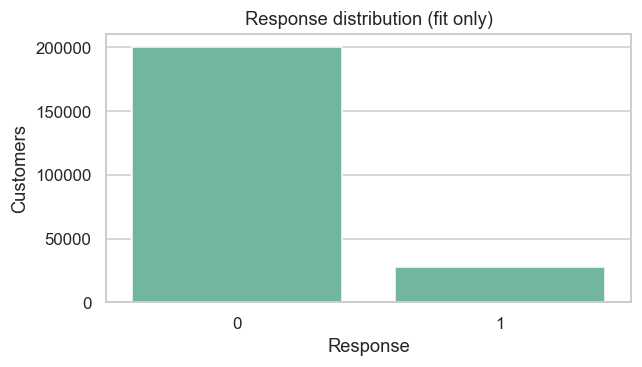

관심 고객 비율: 12.26%
모두 0으로 예측한 정확도: 87.74%, 재현율: 0%


In [5]:
class_table = y_fit.value_counts().sort_index().to_frame('count')
class_table['rate'] = class_table['count'] / len(y_fit)
display(class_table)
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.countplot(x=y_fit, ax=ax)
ax.set(title='Response distribution (fit only)', xlabel='Response', ylabel='Customers')
plt.tight_layout(); plt.show()
print(f'관심 고객 비율: {y_fit.mean():.2%}')
print(f'모두 0으로 예측한 정확도: {1-y_fit.mean():.2%}, 재현율: 0%')

### 2-3. 연속형 변수의 분포와 타깃별 차이
보험료는 큰 값이 일부 존재할 수 있다. 분포를 확인한 후 IQR 제거와 로그변환을 별도 실험한다.

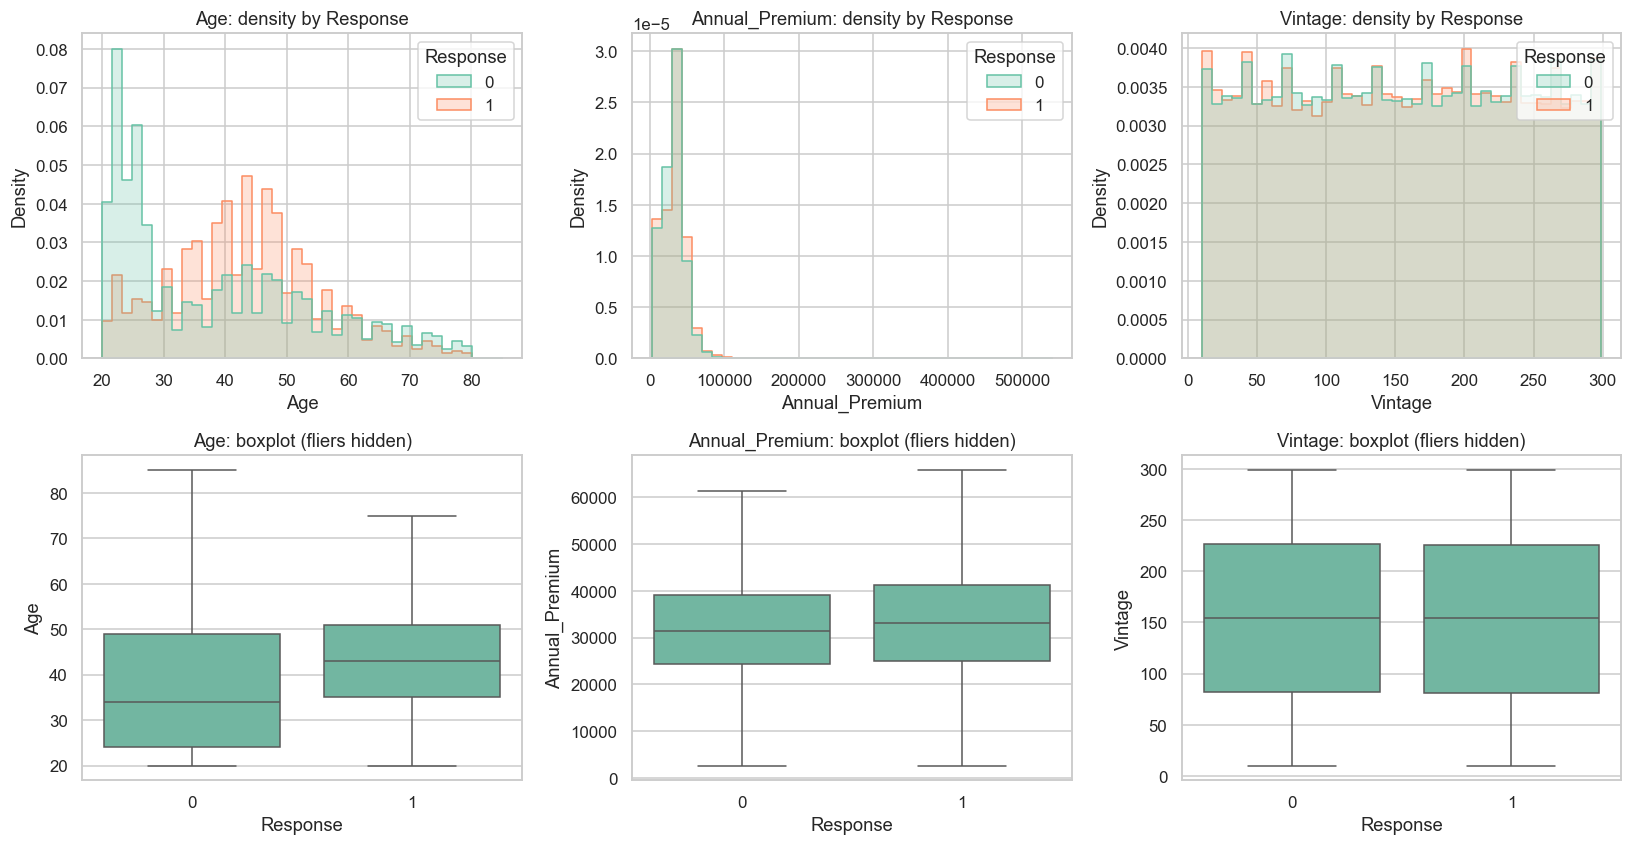

Age            Annual_Premium               Vintage            
         median       mean         median          mean  median        mean
Response                                                                   
0          34.0  38.208718        31520.0  30451.197738   154.0  154.573268
1          43.0  43.503069        33028.0  31612.805038   154.0  154.184757

In [6]:
numeric_eda = ['Age', 'Annual_Premium', 'Vintage']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, column in enumerate(numeric_eda):
    sns.histplot(data=eda, x=column, hue=TARGET, bins=40, element='step',
                 stat='density', common_norm=False, ax=axes[0, j])
    sns.boxplot(data=eda, x=TARGET, y=column, showfliers=False, ax=axes[1, j])
    axes[0, j].set_title(f'{column}: density by Response')
    axes[1, j].set_title(f'{column}: boxplot (fliers hidden)')
plt.tight_layout(); plt.show()
display(eda.groupby(TARGET)[numeric_eda].agg(['median', 'mean']))

### 2-4. 범주별 관심 비율
전체 고객 수가 많은 집단과 관심 비율이 높은 집단을 구분한다. 비율을 해석할 때 표본 수도 함께 확인한다.

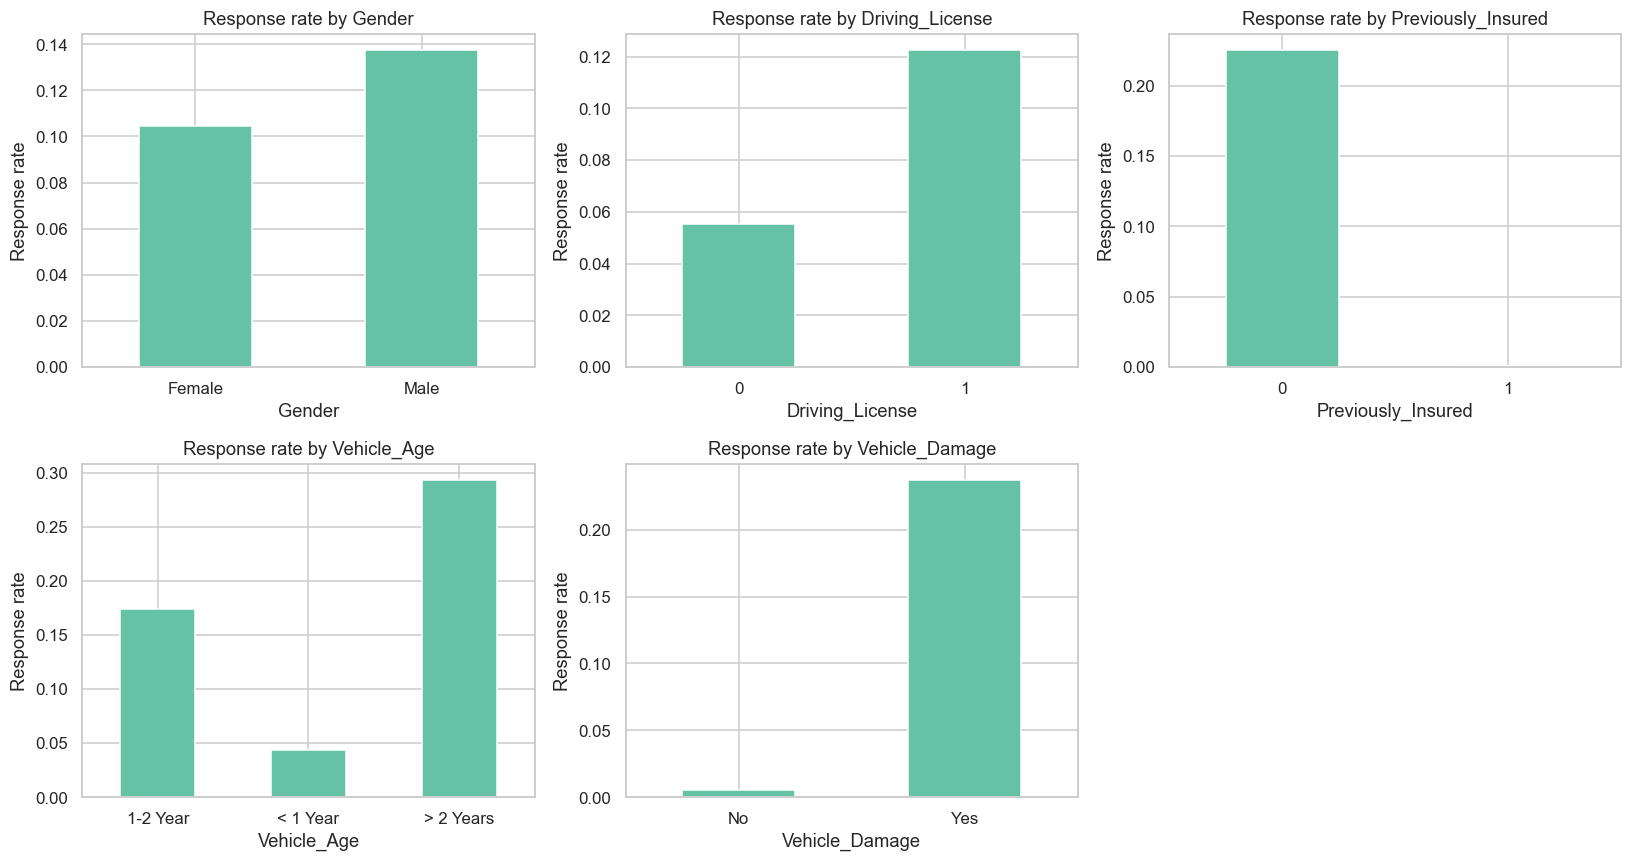

,feature,category,customers,response_rate
0,Gender,Female,104786,0.104728
1,Gender,Male,123879,0.137650
2,Driving_License,0,488,0.055328
3,Driving_License,1,228177,0.122707
4,Previously_Insured,0,123861,0.225567
5,Previously_Insured,1,104804,0.000830
6,Vehicle_Age,1-2 Year,120283,0.173682
7,Vehicle_Age,< 1 Year,98712,0.043500
8,Vehicle_Age,> 2 Years,9670,0.293795
9,Vehicle_Damage,No,113195,0.005398


,customers,response_rate
Region_Code,,
28.0,63801,0.186047
8.0,20337,0.096327
46.0,11865,0.105268
41.0,10960,0.124179
15.0,7885,0.071021
30.0,7249,0.072838
29.0,6688,0.123654
50.0,6190,0.064943
11.0,5567,0.111730


,customers,response_rate
Policy_Sales_Channel,,
152.0,80910,0.028204
26.0,47863,0.200092
124.0,44406,0.189997
160.0,12985,0.021563
156.0,6361,0.211759
122.0,5927,0.175131
157.0,4078,0.268759
154.0,3590,0.243175
151.0,2319,0.035791


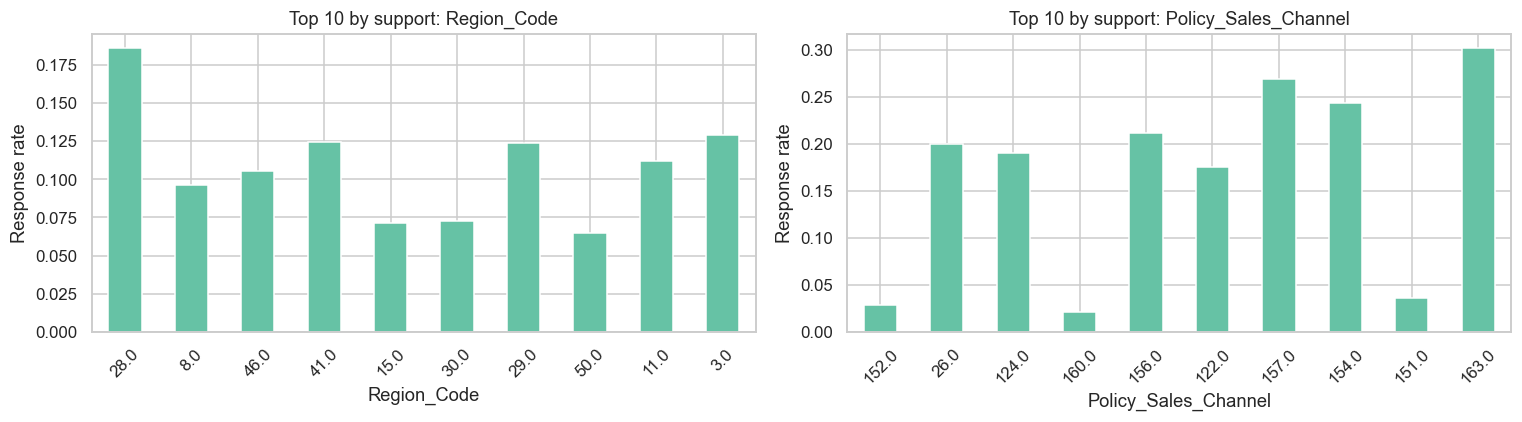

In [7]:
small_categories = ['Gender', 'Driving_License', 'Previously_Insured',
                    'Vehicle_Age', 'Vehicle_Damage']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
category_tables = []
for ax, column in zip(axes.flat, small_categories):
    table = eda.groupby(column)[TARGET].agg(['size', 'mean']).reset_index()
    table.columns = [column, 'customers', 'response_rate']
    table.plot.bar(x=column, y='response_rate', ax=ax, legend=False, rot=0)
    ax.set(title=f'Response rate by {column}', ylabel='Response rate')
    table.insert(0, 'feature', column)
    category_tables.append(table.rename(columns={column: 'category'}))
axes.flat[-1].axis('off')
plt.tight_layout(); plt.show()
category_summary = pd.concat(category_tables, ignore_index=True)
display(category_summary)
category_summary.to_csv(OUT_DIR / 'category_response_rates.csv', index=False)

# 명목형 코드: 큰 숫자가 더 우수한 지역·채널이라는 의미가 아니다.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, column in zip(axes, ['Region_Code', 'Policy_Sales_Channel']):
    table = eda.groupby(column)[TARGET].agg(['size', 'mean'])
    table = table.nlargest(10, 'size')
    display(table.rename(columns={'size': 'customers', 'mean': 'response_rate'}))
    table['mean'].plot.bar(ax=ax, rot=45)
    ax.set(title=f'Top 10 by support: {column}', ylabel='Response rate')
plt.tight_layout(); plt.show()

### 2-5. 피처 간 상관관계
연속형·이진 변수만 피어슨 상관계수로 확인한다. 지역·채널의 코드 숫자는 제외한다.
높은 상관관계가 있으면 변수들이 겹치는 정보를 줄 수 있다. 상관관계와 예측 중요도는 인과관계가 아니다.

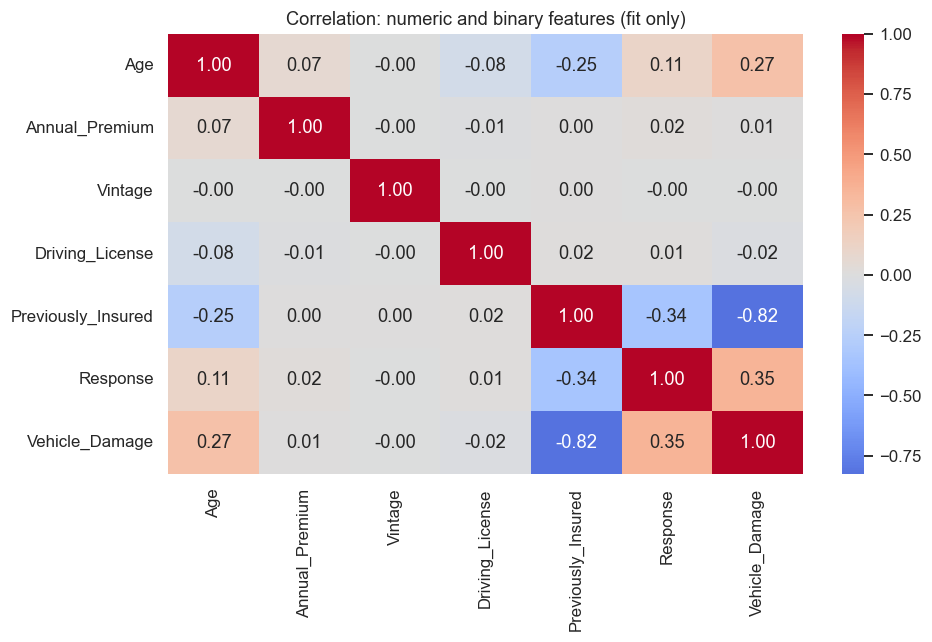

correlation
Previously_Insured Vehicle_Damage        -0.824484
Age                Vehicle_Damage         0.267162
                   Previously_Insured    -0.254353
                   Driving_License       -0.079269
                   Annual_Premium         0.067510
Driving_License    Vehicle_Damage        -0.016788
                   Previously_Insured     0.015532
Annual_Premium     Driving_License       -0.010273

**EDA에서 확인한 관계:** 기존 차량보험 미보유 고객의 관심 비율은 22.56%, 보유 고객은 0.08%입니다. 손상 경험 Yes는 23.74%, No는 0.54%입니다. 이는 이 표본에서의 연관성이며 손상이 관심을 발생시킨다는 인과적 결론은 아닙니다.

In [8]:
corr_data = eda[['Age', 'Annual_Premium', 'Vintage', 'Driving_License',
                 'Previously_Insured', TARGET]].copy()
corr_data['Vehicle_Damage'] = eda['Vehicle_Damage'].map({'No': 0, 'Yes': 1})
corr = corr_data.corr()
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation: numeric and binary features (fit only)')
plt.tight_layout(); plt.show()

feature_corr = corr.drop(index=TARGET, columns=TARGET)
pairs = feature_corr.where(np.triu(np.ones(feature_corr.shape), k=1).astype(bool)).stack()
display(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(8).to_frame('correlation'))
corr.to_csv(OUT_DIR / 'correlation.csv')

insured_rates = eda.groupby('Previously_Insured')[TARGET].mean()
damage_rates = eda.groupby('Vehicle_Damage')[TARGET].mean()
display(Markdown(
    f"**EDA에서 확인한 관계:** 기존 차량보험 미보유 고객의 관심 비율은 {insured_rates.loc[0]:.2%}, "
    f"보유 고객은 {insured_rates.loc[1]:.2%}입니다. "
    f"손상 경험 Yes는 {damage_rates.loc['Yes']:.2%}, No는 {damage_rates.loc['No']:.2%}입니다. "
    "이는 이 표본에서의 연관성이며 손상이 관심을 발생시킨다는 인과적 결론은 아닙니다."))

## 3. 전처리와 피처 엔지니어링
### 3-1. 이상치 탐색과 처리 계획
수업의 `Q1 - 1.5×IQR`, `Q3 + 1.5×IQR` 기준으로 보험료의 통계적 이상치를 표시한다.
보험료가 크거나 특정 금액이 반복된다는 이유만으로 오류라고 단정하지 않는다.

기본값은 **원본 유지**이다. 뒤에서 같은 모델로 원본 유지/학습행 IQR 제거를 검증셋에서 비교한다.
삭제 기준은 학습 데이터에서만 구하고, 검증·최종 평가·제출 데이터의 행은 삭제하지 않는다.

,lower,upper,outlier_count,outlier_rate
0,1865.0,61969.0,6260,0.027376


,size,mean
outlier,,
False,222405,0.121715
True,6260,0.152716


보험료 최빈값: 2630.0


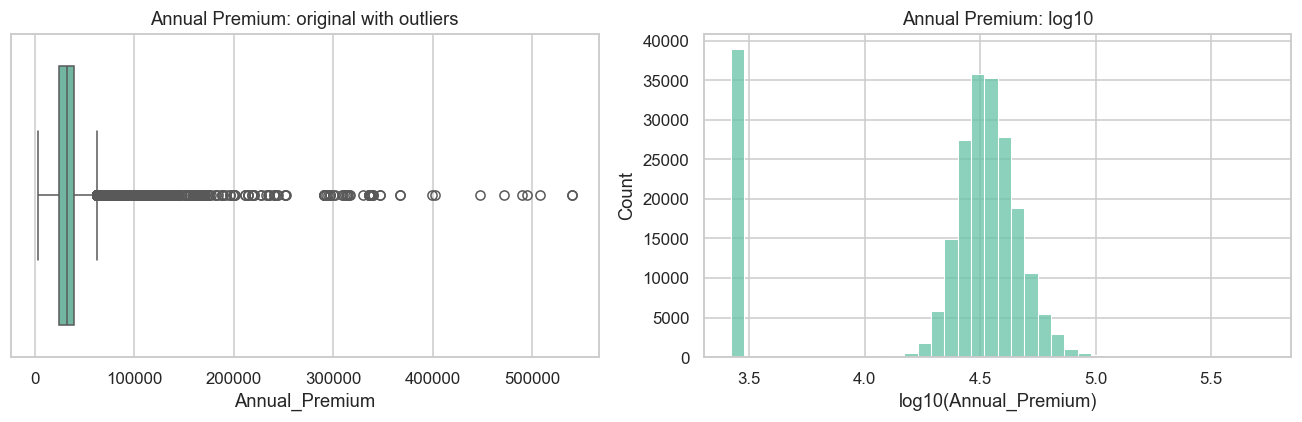

In [9]:
def premium_iqr_bounds(frame):
    q1, q3 = frame['Annual_Premium'].quantile([0.25, 0.75])
    iqr = q3 - q1
    return float(q1 - 1.5 * iqr), float(q3 + 1.5 * iqr)

lower, upper = premium_iqr_bounds(X_fit)
premium_outlier = ~X_fit['Annual_Premium'].between(lower, upper)
display(pd.DataFrame({
    'lower': [lower], 'upper': [upper],
    'outlier_count': [int(premium_outlier.sum())],
    'outlier_rate': [premium_outlier.mean()],
}))
display(pd.DataFrame({'outlier': premium_outlier, 'Response': y_fit})
        .groupby('outlier')['Response'].agg(['size', 'mean']))
print('보험료 최빈값:', X_fit['Annual_Premium'].mode().iloc[0])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=X_fit['Annual_Premium'], ax=axes[0])
sns.histplot(np.log10(X_fit['Annual_Premium']), bins=40, ax=axes[1])
axes[0].set_title('Annual Premium: original with outliers')
axes[1].set(title='Annual Premium: log10', xlabel='log10(Annual_Premium)')
plt.tight_layout(); plt.show()

### 3-2. 변환 규칙

- `Vehicle_Damage`: No→0, Yes→1. `Vehicle_Age`: 1년 미만→0, 1~2년→1, 2년 초과→2. 순서만 표현하며 실제 연수를 뜻하지 않는다.
- `Gender`, `Region_Code`, `Policy_Sales_Channel`: 명목형이므로 원핫 인코딩. 처음 보는 범주는 인코더의 `handle_unknown='ignore'`로 처리한다.
- 로지스틱 회귀의 수치형 변수는 `StandardScaler`를 사용한다. 트리 모델은 스케일링하지 않는다.
- 현재 학습 데이터는 결측이 없다. 새로운 파일에 결측이 있으면 자동 진행하지 않고 처리 정책을 먼저 재검토한다.
- 파생변수 실험은 두 개만 추가한다: **보험료 로그값**, **기존 차량보험 미보유이면서 손상 경험이 있는지**.
  각각 치우친 분포 표현과 두 조건의 조합을 시험하기 위한 가설이다. 성능 개선은 검증 결과로 확인한다.

아래 함수의 매핑·로그는 각 행의 값에 고정 공식을 적용하므로 데이터에서 통계량이나 타깃 정보를 학습하지 않는다.

In [10]:
def prepare_features(frame, engineered=False):
    assert not frame.isna().any().any(), '원본에 결측값이 있습니다. 처리 정책을 먼저 정하세요.'
    result = frame.copy()
    result['Vehicle_Damage'] = result['Vehicle_Damage'].map({'No': 0, 'Yes': 1})
    result['Vehicle_Age'] = result['Vehicle_Age'].map(
        {'< 1 Year': 0, '1-2 Year': 1, '> 2 Years': 2})
    for column in ['Region_Code', 'Policy_Sales_Channel']:
        result[column] = result[column].astype(str)
    if engineered:
        result['Log_Annual_Premium'] = np.log10(result['Annual_Premium'])
        result['Uninsured_Damaged'] = (
            (result['Previously_Insured'] == 0) & (result['Vehicle_Damage'] == 1)
        ).astype(int)
    assert not result.isna().any().any(), '결측값이나 예상하지 못한 범주가 있습니다.'
    return result

X_fit_base = prepare_features(X_fit)
display(X_fit_base.head())

,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage
257796,Male,45,1,41.0,0,1,1,33056.0,124.0,128
224511,Female,37,1,28.0,1,1,0,25765.0,152.0,162
15821,Male,68,1,20.0,0,1,0,2630.0,124.0,36
179652,Female,24,1,8.0,0,0,1,31659.0,152.0,292
376338,Male,30,1,6.0,0,1,1,27221.0,154.0,111


### 3-3. 교차검증마다 전처리를 다시 학습하기
`ColumnTransformer`는 열별 처리를 연결하고, `Pipeline`은 **전처리 → 모델** 순서를 연결한다.
`GridSearchCV`가 fold를 나눈 뒤 이 파이프라인 전체를 fit하므로 인코더와 스케일러가 검증 fold를 먼저 볼 수 없다.

In [11]:
CATEGORY_COLUMNS = ['Gender', 'Region_Code', 'Policy_Sales_Channel']

def make_pipeline(model_name, estimator, feature_frame):
    numeric_columns = [c for c in feature_frame.columns if c not in CATEGORY_COLUMNS]
    numeric_step = StandardScaler() if model_name == 'LogisticRegression' else 'passthrough'
    preprocess = ColumnTransformer([
        ('numeric', numeric_step, numeric_columns),
        ('category', OneHotEncoder(handle_unknown='ignore', dtype=np.float32), CATEGORY_COLUMNS),
    ], sparse_threshold=1.0)
    return Pipeline([('preprocess', preprocess), ('model', clone(estimator))])

def metric_values(truth, probability, threshold=0.5):
    predicted = (probability >= threshold).astype(int)
    return {
        'ROC_AUC': roc_auc_score(truth, probability),
        'AP': average_precision_score(truth, probability),
        'Accuracy': accuracy_score(truth, predicted),
        'Precision': precision_score(truth, predicted, zero_division=0),
        'Recall': recall_score(truth, predicted, zero_division=0),
        'F1': f1_score(truth, predicted, zero_division=0),
    }

## 4. 베이스라인 → 모델 비교

|모델|선택 이유|초기 복잡도 제어|
|---|---|---|
|모두 0 예측|높은 정확도만으로 충분하지 않음을 확인하는 단순 기준|학습 없음|
|로지스틱 회귀|선형 관계만으로 얻는 성능 기준|C=1, 최대 반복 1,000|
|결정트리|조건 분기의 효과를 이해하기 쉬움|깊이 6, 리프 최소 50명|
|랜덤포레스트|여러 나무의 평균으로 단일 나무의 변동 완화|나무 100개, 깊이 12, 리프 최소 20명|
|XGBoost|앞선 나무의 오차를 순차적으로 개선|나무 150개, 깊이 3, 학습률 0.05|
|LightGBM|수업에서 배운 빠른 부스팅 모델과 비교|나무 150개, 리프 15개, 학습률 0.05|

학습 행을 일부 추출하거나 클래스 비율을 바꾸지 않는다. 모든 모델에 동일한 학습행·3개 층화 fold를 적용한다.
3-fold는 38만 행 데이터의 실행 시간과 평가 안정성을 절충한 선택이다.
학습 ROC-AUC와 검증 ROC-AUC 차이도 함께 확인한다. CV 표의 Precision/Recall/F1은 모두 임계값 0.5 기준이다.

In [12]:
models = {
    'LogisticRegression': LogisticRegression(C=1.0, max_iter=1000, solver='lbfgs', random_state=SEED),
    'DecisionTree': DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=SEED),
    'RandomForest': RandomForestClassifier(n_estimators=100, max_depth=12,
        min_samples_leaf=20, n_jobs=N_JOBS, random_state=SEED),
    'XGBoost': XGBClassifier(n_estimators=150, max_depth=3, learning_rate=0.05,
        min_child_weight=10, subsample=1.0, colsample_bytree=1.0,
        tree_method='hist', eval_metric='logloss', n_jobs=N_JOBS, random_state=SEED),
    'LightGBM': LGBMClassifier(n_estimators=150, num_leaves=15, learning_rate=0.05,
        min_child_samples=50, subsample=1.0, colsample_bytree=1.0,
        n_jobs=N_JOBS, random_state=SEED, verbosity=-1,
        deterministic=True, force_col_wise=True),
}
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
fold_indices = list(cv.split(X_fit_base, y_fit))

baseline = metric_values(y_fit, np.zeros(len(y_fit)))
display(pd.DataFrame([baseline], index=['Always 0 (fit reference only)']))

,ROC_AUC,AP,Accuracy,Precision,Recall,F1
Always 0 (fit reference only),0.5,0.122564,0.877436,0.0,0.0,0.0


In [13]:
# 각 fold에서 학습 → 확률 예측 → 평가하는 순서를 직접 확인한다.
cv_rows = []
for model_name, estimator in models.items():
    print('CV 시작:', model_name, flush=True)
    for fold, (train_index, valid_index) in enumerate(fold_indices, start=1):
        fold_train = X_fit_base.iloc[train_index]
        fold_valid = X_fit_base.iloc[valid_index]
        fold_y_train = y_fit.iloc[train_index]
        fold_y_valid = y_fit.iloc[valid_index]
        pipeline = make_pipeline(model_name, estimator, fold_train)
        start = time.perf_counter()
        pipeline.fit(fold_train, fold_y_train)
        valid_probability = pipeline.predict_proba(fold_valid)[:, 1]
        train_probability = pipeline.predict_proba(fold_train)[:, 1]
        row = {'model': model_name, 'fold': fold,
               'parameters': json.dumps(estimator.get_params(), default=str, sort_keys=True),
               'seconds': time.perf_counter() - start,
               'Train_ROC_AUC': roc_auc_score(fold_y_train, train_probability),
               **metric_values(fold_y_valid, valid_probability)}
        cv_rows.append(row)
        print(f"  fold {fold}: ROC-AUC={row['ROC_AUC']:.5f}", flush=True)

cv_log = pd.DataFrame(cv_rows)
comparison = cv_log.groupby('model').agg(
    CV_ROC_AUC=('ROC_AUC', 'mean'), CV_STD=('ROC_AUC', lambda values: values.std(ddof=0)),
    CV_AP=('AP', 'mean'), CV_Accuracy=('Accuracy', 'mean'),
    CV_Precision=('Precision', 'mean'), CV_Recall=('Recall', 'mean'), CV_F1=('F1', 'mean'),
    Train_ROC_AUC=('Train_ROC_AUC', 'mean'), mean_seconds=('seconds', 'mean'),
).sort_values('CV_ROC_AUC', ascending=False)
comparison['train_cv_gap'] = comparison['Train_ROC_AUC'] - comparison['CV_ROC_AUC']
display(comparison.round(5))
cv_log.to_csv(OUT_DIR / 'model_cv_folds.csv', index=False)
comparison.to_csv(OUT_DIR / 'model_comparison.csv')

CV 시작: LogisticRegression


  fold 1: ROC-AUC=0.84730


  fold 2: ROC-AUC=0.84787


  fold 3: ROC-AUC=0.85001


CV 시작: DecisionTree


...

CV 시작: LightGBM


  fold 1: ROC-AUC=0.85536


  fold 2: ROC-AUC=0.85632


  fold 3: ROC-AUC=0.85774


,CV_ROC_AUC,CV_STD,CV_AP,CV_Accuracy,CV_Precision,CV_Recall,CV_F1,Train_ROC_AUC,mean_seconds,train_cv_gap
model,,,,,,,,,,
LightGBM,0.85647,0.00098,0.36582,0.87746,0.53312,0.00089,0.00178,0.86070,0.82772,0.00423
XGBoost,0.85329,0.00106,0.35668,0.87744,0.00000,0.00000,0.00000,0.85454,0.47723,0.00126
RandomForest,0.85042,0.00140,0.35299,0.87744,0.00000,0.00000,0.00000,0.85585,1.36775,0.00544
LogisticRegression,0.84839,0.00117,0.33415,0.87723,0.33669,0.00164,0.00327,0.85037,1.56638,0.00198
DecisionTree,0.84284,0.00050,0.32036,0.87744,0.00000,0.00000,0.00000,0.84419,0.33377,0.00135


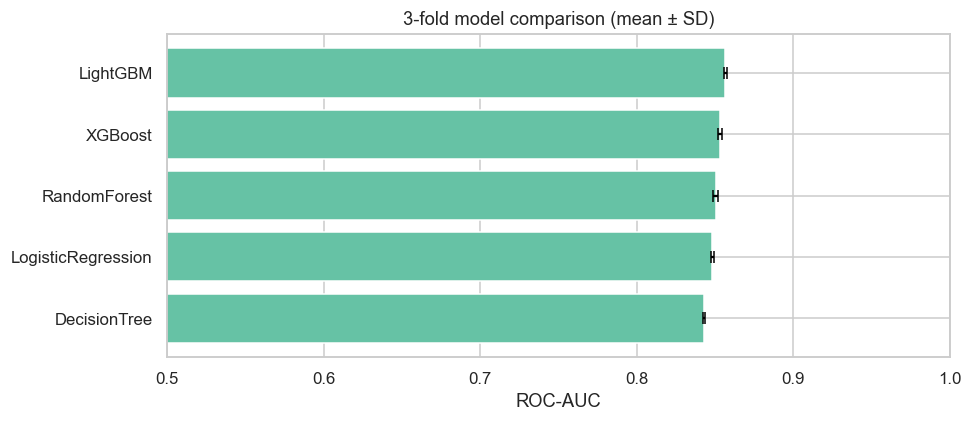

초기 CV 1위는 **LightGBM**입니다. 표준편차는 ddof=0으로 통일한 fold 사이 변동이며 신뢰구간이나 통계적 유의성 검정이 아닙니다. 점수가 조금 높다는 이유만으로 다른 모델보다 확실히 우수하다고 결론 내리지 않습니다.

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(comparison.index, comparison['CV_ROC_AUC'], xerr=comparison['CV_STD'], capsize=4)
ax.invert_yaxis()
ax.set(xlim=(0.5, 1.0), xlabel='ROC-AUC', title='3-fold model comparison (mean ± SD)')
plt.tight_layout(); plt.show()
display(Markdown(
    f"초기 CV 1위는 **{comparison.index[0]}**입니다. "
    "표준편차는 ddof=0으로 통일한 fold 사이 변동이며 신뢰구간이나 통계적 유의성 검정이 아닙니다. "
    "점수가 조금 높다는 이유만으로 다른 모델보다 확실히 우수하다고 결론 내리지 않습니다."))

## 5. 하이퍼파라미터 튜닝과 실험 로그
### 5-1. 탐색 계획을 고정한 뒤 GridSearchCV 실행

초기 CV 상위 **두 모델**만 튜닝해 계산량을 제한한다. 각 후보는 다시 같은 3-fold로 비교한다.
원본 전처리 조건에서 ROC-AUC가 높은 설정을 선택한다. 최종 보관 평가셋은 사용하지 않는다.
초기 모델 설정도 최종 후보에 남겨 튜닝 때문에 기존 성능을 잃지 않게 한다.

|모델|탐색 범위|이유|
|---|---|---|
|로지스틱 회귀|C: 0.1, 1, 10|규제 강도를 바꿔 선형 모델의 복잡도 비교|
|결정트리|깊이: 4, 6, 10 / 리프 최소: 20, 50|세부 분할과 과적합의 균형|
|랜덤포레스트|깊이: 10, 16 / 리프 최소: 10, 30 / 나무: 100|지나치게 깊은 나무를 제한|
|XGBoost|깊이: 3, 5 / 학습률: 0.05, 0.1 / 나무: 150, 250|복잡도·학습 속도·반복량의 균형|
|LightGBM|리프: 15, 31 / 학습률: 0.05, 0.1 / 나무: 150, 250|분할의 세밀함과 학습량 조절|

조기 종료는 사용하지 않아 평가셋을 학습 과정에 전달하지 않는다. 여러 모델의 동시 학습 대신 각 모델 내부에 최대 4개 작업을 사용한다.

In [15]:
parameter_grids = {
    'LogisticRegression': {'model__C': [0.1, 1.0, 10.0]},
    'DecisionTree': {'model__max_depth': [4, 6, 10], 'model__min_samples_leaf': [20, 50]},
    'RandomForest': {'model__max_depth': [10, 16], 'model__min_samples_leaf': [10, 30],
                     'model__n_estimators': [100]},
    'XGBoost': {'model__max_depth': [3, 5], 'model__learning_rate': [0.05, 0.1],
                'model__n_estimators': [150, 250]},
    'LightGBM': {'model__num_leaves': [15, 31], 'model__learning_rate': [0.05, 0.1],
                 'model__n_estimators': [150, 250]},
}
tune_names = comparison.head(2).index.tolist()
grid_logs = []
candidate_estimators = {}
candidate_rows = []

for model_name, estimator in models.items():
    label = model_name + '_initial'
    candidate_estimators[label] = clone(estimator)
    candidate_rows.append({'candidate': label, 'model': model_name,
                          'CV_ROC_AUC': comparison.loc[model_name, 'CV_ROC_AUC'],
                          'CV_STD': comparison.loc[model_name, 'CV_STD']})

for model_name in tune_names:
    print('튜닝 시작:', model_name, flush=True)
    search = GridSearchCV(
        make_pipeline(model_name, models[model_name], X_fit_base),
        param_grid=parameter_grids[model_name],
        scoring={'roc_auc': 'roc_auc', 'AP': 'average_precision'},
        refit='roc_auc', cv=fold_indices, n_jobs=1,
        return_train_score=True, error_score='raise',
    )
    search.fit(X_fit_base, y_fit)
    log = pd.DataFrame(search.cv_results_)
    log.insert(0, 'model', model_name)
    grid_logs.append(log)
    label = model_name + '_tuned'
    candidate_estimators[label] = clone(search.best_estimator_.named_steps['model'])
    candidate_rows.append({'candidate': label, 'model': model_name,
                          'CV_ROC_AUC': search.best_score_,
                          'CV_STD': log.loc[search.best_index_, 'std_test_roc_auc']})
    print('최고 설정:', search.best_params_, '| CV ROC-AUC:', round(search.best_score_, 5), flush=True)

tuning_log = pd.concat(grid_logs, ignore_index=True)
tuning_log['params'] = tuning_log['params'].map(lambda x: json.dumps(x, sort_keys=True))
tuning_log.to_csv(OUT_DIR / 'grid_search_results.csv', index=False)
display(tuning_log[['model', 'params', 'mean_train_roc_auc', 'mean_test_roc_auc',
                    'std_test_roc_auc', 'mean_test_AP', 'mean_fit_time']]
        .sort_values('mean_test_roc_auc', ascending=False).head(12))

candidates = pd.DataFrame(candidate_rows).sort_values('CV_ROC_AUC', ascending=False)
best_candidate = candidates.iloc[0]
best_name = best_candidate['model']
best_estimator = candidate_estimators[best_candidate['candidate']]
display(candidates)
print('CV에서 선정한 모델:', best_candidate['candidate'])
print('선정 파라미터:', best_estimator.get_params())
candidates.to_csv(OUT_DIR / 'model_selection.csv', index=False)

튜닝 시작: LightGBM


최고 설정: {'model__learning_rate': 0.05, 'model__n_estimators': 150, 'model__num_leaves': 31} | CV ROC-AUC: 0.85669


튜닝 시작: XGBoost


최고 설정: {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 150} | CV ROC-AUC: 0.85655


,model,params,mean_train_roc_auc,mean_test_roc_auc,std_test_roc_auc,mean_test_AP,mean_fit_time
1,LightGBM,"{""model__learning_rate"": 0.05, ""model__n_estimators"": 150, ""model__num_leaves"": 31}",0.866334,0.856688,0.001206,0.367142,0.728387
2,LightGBM,"{""model__learning_rate"": 0.05, ""model__n_estimators"": 250, ""model__num_leaves"": 15}",0.864508,0.856681,0.001063,0.365776,0.818555
14,XGBoost,"{""model__learning_rate"": 0.1, ""model__max_depth"": 5, ""model__n_estimators"": 150}",0.864567,0.856548,0.001317,0.365925,0.370328
4,LightGBM,"{""model__learning_rate"": 0.1, ""model__n_estimators"": 150, ""model__num_leaves"": 15}",0.865958,0.856483,0.001116,0.365101,0.525826
3,LightGBM,"{""model__learning_rate"": 0.05, ""model__n_estimators"": 250, ""model__num_leaves"": 31}",0.872698,0.856481,0.001316,0.366382,1.000331
0,LightGBM,"{""model__learning_rate"": 0.05, ""model__n_estimators"": 150, ""model__num_leaves"": 15}",0.860699,0.856474,0.000976,0.365817,0.602059
13,XGBoost,"{""model__learning_rate"": 0.1, ""model__max_depth"": 3, ""model__n_estimators"": 250}",0.861325,0.856470,0.001256,0.364476,0.407914
15,XGBoost,"{""model__learning_rate"": 0.1, ""model__max_depth"": 5, ""model__n_estimators"": 250}",0.869564,0.856409,0.001451,0.365845,0.478322
11,XGBoost,"{""model__learning_rate"": 0.05, ""model__max_depth"": 5, ""model__n_estimators"": 250}",0.862913,0.856390,0.001187,0.365604,0.505720
6,LightGBM,"{""model__learning_rate"": 0.1, ""model__n_estimators"": 250, ""model__num_leaves"": 15}",0.871674,0.856185,0.001165,0.364768,0.758607


,candidate,model,CV_ROC_AUC,CV_STD
5,LightGBM_tuned,LightGBM,0.856688,0.001206
6,XGBoost_tuned,XGBoost,0.856548,0.001317
4,LightGBM_initial,LightGBM,0.856474,0.000976
3,XGBoost_initial,XGBoost,0.853288,0.001059
2,RandomForest_initial,RandomForest,0.850420,0.001404
0,LogisticRegression_initial,LogisticRegression,0.848392,0.001166
1,DecisionTree_initial,DecisionTree,0.842841,0.000502


CV에서 선정한 모델: LightGBM_tuned
선정 파라미터: {'boosting_type': 'gbdt', 'class_weight': None, 'colsample_bytree': 1.0, 'importance_type': 'split', 'learning_rate': 0.05, 'max_depth': -1, 'min_child_samples': 50, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 150, 'n_jobs': 4, 'num_leaves': 31, 'objective': None, 'random_state': 42, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 1.0, 'subsample_for_bin': 200000, 'subsample_freq': 0, 'verbosity': -1, 'deterministic': True, 'force_col_wise': True}


### 5-2. 이상치 제거·파생변수의 효과 비교
위에서 고른 **동일한 모델·파라미터**로 아래 네 조건을 사전에 정해 비교한다.
1. 원본 유지 / 2. IQR 밖의 학습행 제거 / 3. 파생변수 추가 / 4. 두 방법 함께 적용.

**선택 규칙:** 검증 ROC-AUC 최댓값에서 0.001 이내인 조건 중 변경 사항이 적은 조건을 선택한다.
동률이면 학습행을 보존하는 조건을 우선한다. 0.001은 통계적 유의성 기준이 아니라 미세한 점수 차이로
정상 고객을 제외하거나 복잡도를 늘리지 않기 위한 프로젝트의 사전 규칙이다.
이 네 조건만 비교하고 holdout 결과를 보고 다시 수정하지 않는다.

In [16]:
experiment_specs = [
    {'name': 'original', 'remove_iqr': False, 'engineered': False},
    {'name': 'remove_iqr', 'remove_iqr': True, 'engineered': False},
    {'name': 'engineered', 'remove_iqr': False, 'engineered': True},
    {'name': 'remove_iqr_and_engineered', 'remove_iqr': True, 'engineered': True},
]
experiment_rows = []
experiment_models = {}
experiment_valid_probabilities = {}
for spec in experiment_specs:
    keep = (~premium_outlier) if spec['remove_iqr'] else pd.Series(True, index=X_fit.index)
    current_train = prepare_features(X_fit.loc[keep], spec['engineered'])
    current_valid = prepare_features(X_valid, spec['engineered'])
    pipeline = make_pipeline(best_name, best_estimator, current_train)
    start = time.perf_counter()
    pipeline.fit(current_train, y_fit.loc[keep])
    probability = pipeline.predict_proba(current_valid)[:, 1]
    experiment_models[spec['name']] = pipeline
    experiment_valid_probabilities[spec['name']] = probability
    experiment_rows.append({**spec, 'fit_rows': len(current_train),
        'removed_rows': len(X_fit) - len(current_train),
        'changes': int(spec['remove_iqr']) + int(spec['engineered']),
        'seconds': time.perf_counter() - start,
        **metric_values(y_valid, probability)})

experiments = pd.DataFrame(experiment_rows)
max_validation_auc = experiments['ROC_AUC'].max()
eligible = experiments[experiments['ROC_AUC'] >= max_validation_auc - 0.001]
chosen = eligible.sort_values(['changes', 'remove_iqr', 'ROC_AUC'],
                             ascending=[True, True, False]).iloc[0]
selected_spec = next(s for s in experiment_specs if s['name'] == chosen['name'])
final_model = experiment_models[chosen['name']]
valid_probability = experiment_valid_probabilities[chosen['name']]
display(experiments.round(5))
display(Markdown(f"선정 조건: **{chosen['name']}**. "
                 f"학습행 {int(chosen['removed_rows']):,}개 제거, "
                 f"검증 ROC-AUC {chosen['ROC_AUC']:.5f}. "
                 "검증셋은 조건 선택에 사용했으므로 독립적인 성능 추정치가 아닙니다."))
experiments.to_csv(OUT_DIR / 'preprocessing_experiments.csv', index=False)

,name,remove_iqr,engineered,fit_rows,removed_rows,changes,seconds,ROC_AUC,AP,Accuracy,Precision,Recall,F1
0,original,False,False,228665,0,0,1.01355,0.85794,0.37402,0.87761,0.62264,0.00353,0.00703
1,remove_iqr,True,False,222405,6260,1,0.99820,0.85786,0.37284,0.87744,0.50000,0.00310,0.00617
2,engineered,False,True,228665,0,1,1.08780,0.85797,0.37372,0.87762,0.64000,0.00343,0.00681
3,remove_iqr_and_engineered,True,True,222405,6260,2,1.18202,0.85784,0.37298,0.87767,0.71429,0.00321,0.00639


선정 조건: **original**. 학습행 0개 제거, 검증 ROC-AUC 0.85794. 검증셋은 조건 선택에 사용했으므로 독립적인 성능 추정치가 아닙니다.

### 5-3. 선정한 전처리까지 포함한 교차검증 기록
최종 구성도 학습 데이터 안에서 3-fold로 확인한다. IQR 제거가 선택됐다면 각 fold의 학습 부분에서
경계를 다시 계산한다. 원본 조건이 선정된 경우 앞서 얻은 동일한 CV 결과를 재사용한다.
이 표는 선택 후의 참고 결과이며 새로운 후보 선택에 사용하지 않는다.

In [17]:
if selected_spec['name'] == 'original':
    selected_cv_mean = float(best_candidate['CV_ROC_AUC'])
    selected_cv_std = float(best_candidate['CV_STD'])
else:
    selected_fold_rows = []
    for fold, (train_index, valid_index) in enumerate(fold_indices, 1):
        raw_train = X_fit.iloc[train_index]
        raw_valid = X_fit.iloc[valid_index]
        raw_y = y_fit.iloc[train_index]
        if selected_spec['remove_iqr']:
            fold_lower, fold_upper = premium_iqr_bounds(raw_train)
            keep = raw_train['Annual_Premium'].between(fold_lower, fold_upper)
            raw_train, raw_y = raw_train.loc[keep], raw_y.loc[keep]
        prepared_train = prepare_features(raw_train, selected_spec['engineered'])
        prepared_valid = prepare_features(raw_valid, selected_spec['engineered'])
        pipeline = make_pipeline(best_name, best_estimator, prepared_train)
        pipeline.fit(prepared_train, raw_y)
        probability = pipeline.predict_proba(prepared_valid)[:, 1]
        selected_fold_rows.append({'fold': fold, **metric_values(y_fit.iloc[valid_index], probability)})
    selected_cv_log = pd.DataFrame(selected_fold_rows)
    selected_cv_log.to_csv(OUT_DIR / 'selected_configuration_cv.csv', index=False)
    selected_cv_mean = selected_cv_log['ROC_AUC'].mean()
    selected_cv_std = selected_cv_log['ROC_AUC'].std(ddof=0)
print(f'선정 구성 CV ROC-AUC: {selected_cv_mean:.5f} ± {selected_cv_std:.5f}')

선정 구성 CV ROC-AUC: 0.85669 ± 0.00121


## 6. 임계값 선택 → 최종 평가
### 6-1. 검증셋에서 임계값 고정
관심 확률이 0.5를 넘는 고객이 적으면 기본 임계값에서 재현율이 낮아질 수 있다.
수업처럼 임계값을 0.05~0.50 사이에서 0.05 간격으로 비교한다.
**검증 F1 최대**, 동률이면 정밀도와 임계값이 높은 것을 선택한다.
ROC-AUC와 AP는 확률로 계산하므로 이 임계값 변경으로 달라지지 않는다.

,threshold,ROC_AUC,AP,Accuracy,Precision,Recall,F1
0,0.05,0.85794,0.37402,0.63972,0.25158,0.98212,0.40056
1,0.10,0.85794,0.37402,0.68213,0.27194,0.95012,0.42286
2,0.15,0.85794,0.37402,0.72116,0.29247,0.89852,0.44130
3,0.20,0.85794,0.37402,0.76069,0.31569,0.81578,0.45522
4,0.25,0.85794,0.37402,0.79376,0.33804,0.71248,0.45853
5,0.30,0.85794,0.37402,0.82964,0.36408,0.52227,0.42906
6,0.35,0.85794,0.37402,0.85986,0.40480,0.30497,0.34786
7,0.40,0.85794,0.37402,0.87393,0.44243,0.10983,0.17597
8,0.45,0.85794,0.37402,0.87778,0.52814,0.02612,0.04978
9,0.50,0.85794,0.37402,0.87761,0.62264,0.00353,0.00703


고정한 임계값: 0.25


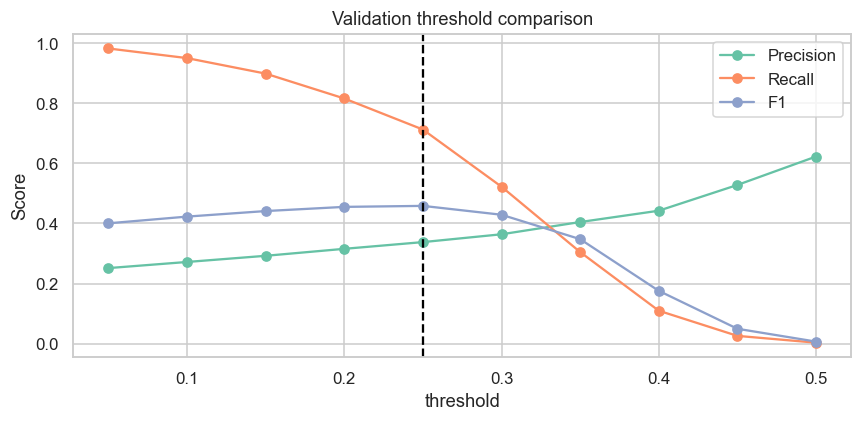

889

In [18]:
threshold_rows = []
for threshold in np.round(np.arange(0.05, 0.51, 0.05), 2):
    threshold_rows.append({'threshold': threshold, **metric_values(y_valid, valid_probability, threshold)})
threshold_table = pd.DataFrame(threshold_rows)
selected_threshold = float(threshold_table.sort_values(
    ['F1', 'Precision', 'threshold'], ascending=False).iloc[0]['threshold'])
display(threshold_table.round(5))
print('고정한 임계값:', selected_threshold)
threshold_table.to_csv(OUT_DIR / 'validation_thresholds.csv', index=False)
fig, ax = plt.subplots(figsize=(8, 4))
threshold_table.plot(x='threshold', y=['Precision', 'Recall', 'F1'], marker='o', ax=ax)
ax.axvline(selected_threshold, color='black', linestyle='--')
ax.set(title='Validation threshold comparison', ylabel='Score')
plt.tight_layout(); plt.show()

frozen_config = {
    'model': best_name, 'parameters': best_estimator.get_params(),
    'preprocessing': selected_spec, 'threshold': selected_threshold,
    'seed': SEED, 'cv_folds': N_SPLITS,
    'selected_cv_roc_auc': selected_cv_mean, 'selected_cv_std': selected_cv_std,
    'holdout_used_for_selection': False,
}
(OUT_DIR / 'selected_config.json').write_text(
    json.dumps(frozen_config, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

### 6-2. 보관했던 holdout을 처음 평가
모델·전처리·임계값을 고정했다. 검증셋에서 평가한 **동일한 학습 모델**을 그대로 사용한다.
여기서 학습+검증으로 재학습하면 확률 분포가 바뀔 수 있으므로, 독립 평가 전에 모델을 바꾸지 않는다.
기본 임계값 0.5와 고정 임계값의 결과를 모두 보고한다. 결과가 기대보다 낮더라도 holdout에 맞춰 다시 튜닝하지 않는다.

In [19]:
holdout_features = prepare_features(X_holdout, selected_spec['engineered'])
holdout_probability = final_model.predict_proba(holdout_features)[:, 1]
fit_probability = final_model.predict_proba(
    prepare_features(X_fit, selected_spec['engineered']))[:, 1]

evaluation_rows = []
for split_name, truth, probability in [
    ('fit_all_rows', y_fit, fit_probability),
    ('validation_used_for_selection', y_valid, valid_probability),
    ('holdout', y_holdout, holdout_probability),
]:
    for threshold in sorted(set([0.5, selected_threshold])):
        evaluation_rows.append({'split': split_name, 'threshold': threshold,
                                **metric_values(truth, probability, threshold)})
evaluation = pd.DataFrame(evaluation_rows)
display(evaluation.round(5))
print('holdout의 단순 모두 0 정확도:', round(1-y_holdout.mean(), 5))
print('holdout의 AP 비교 기준(양성 비율):', round(y_holdout.mean(), 5))

fit_auc = roc_auc_score(y_fit, fit_probability)
holdout_auc = roc_auc_score(y_holdout, holdout_probability)
auc_gap = fit_auc - holdout_auc
print(f'학습 전체 행 ROC-AUC - holdout ROC-AUC: {auc_gap:.5f}')
if selected_spec['remove_iqr']:
    print('fit_all_rows에는 제거된 행도 포함되어 실제 학습에 사용한 행만의 성능과는 다릅니다.')
    used = ~premium_outlier
    print('실제 학습에 사용한 행만의 ROC-AUC:',
          round(roc_auc_score(y_fit.loc[used], fit_probability[used.to_numpy()]), 5))
evaluation.to_csv(OUT_DIR / 'evaluation_metrics.csv', index=False)

holdout_pred = (holdout_probability >= selected_threshold).astype(int)
print(classification_report(y_holdout, holdout_pred, digits=4, zero_division=0))

,split,threshold,ROC_AUC,AP,Accuracy,Precision,Recall,F1
0,fit_all_rows,0.25,0.86375,0.39022,0.79625,0.34257,0.72069,0.46440
1,fit_all_rows,0.50,0.86375,0.39022,0.87775,0.74658,0.00389,0.00774
2,validation_used_for_selection,0.25,0.85794,0.37402,0.79376,0.33804,0.71248,0.45853
3,validation_used_for_selection,0.50,0.85794,0.37402,0.87761,0.62264,0.00353,0.00703
4,holdout,0.25,0.85768,0.36953,0.79369,0.33774,0.71109,0.45796
5,holdout,0.50,0.85768,0.36953,0.87753,0.57143,0.00300,0.00596


holdout의 단순 모두 0 정확도: 0.87744
holdout의 AP 비교 기준(양성 비율): 0.12256
학습 전체 행 ROC-AUC - holdout ROC-AUC: 0.00608
              precision    recall  f1-score   support

           0     0.9523    0.8052    0.8726     66880
           1     0.3377    0.7111    0.4580      9342

    accuracy                         0.7937     76222
   macro avg     0.6450    0.7582    0.6653     76222
weighted avg     0.8770    0.7937    0.8218     76222



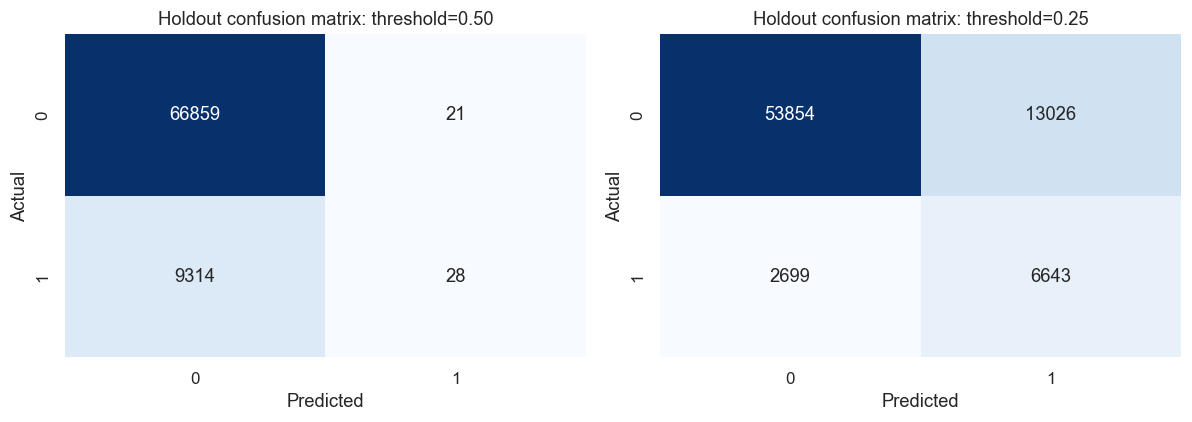

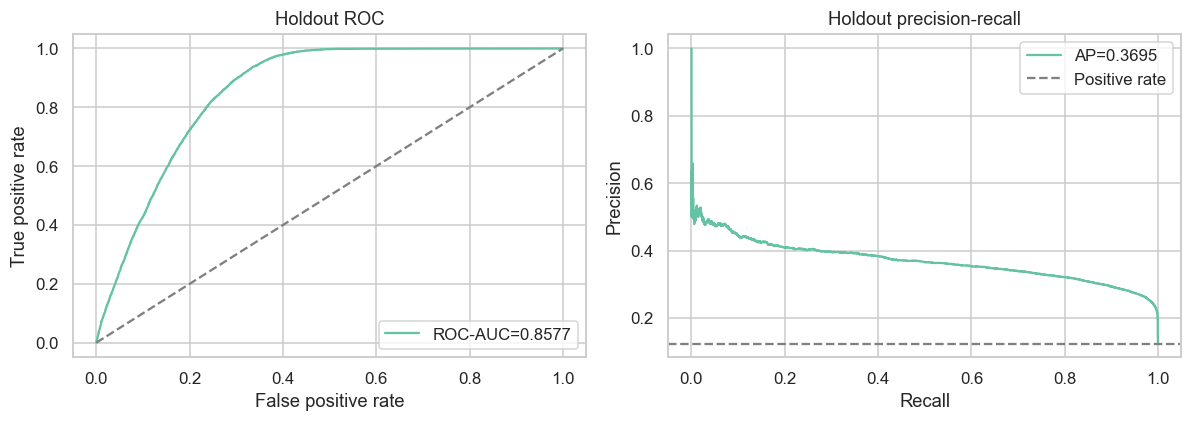

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, threshold in zip(axes, [0.5, selected_threshold]):
    matrix = confusion_matrix(y_holdout, (holdout_probability >= threshold).astype(int))
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set(title=f'Holdout confusion matrix: threshold={threshold:.2f}',
           xlabel='Predicted', ylabel='Actual')
plt.tight_layout(); plt.show()

fpr, tpr, _ = roc_curve(y_holdout, holdout_probability)
precision, recall, _ = precision_recall_curve(y_holdout, holdout_probability)
holdout_ap = average_precision_score(y_holdout, holdout_probability)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(fpr, tpr, label=f'ROC-AUC={holdout_auc:.4f}')
axes[0].plot([0, 1], [0, 1], '--', color='grey')
axes[0].set(title='Holdout ROC', xlabel='False positive rate', ylabel='True positive rate')
axes[1].plot(recall, precision, label=f'AP={holdout_ap:.4f}')
axes[1].axhline(y_holdout.mean(), linestyle='--', color='grey', label='Positive rate')
axes[1].set(title='Holdout precision-recall', xlabel='Recall', ylabel='Precision')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

## 7. 결과 해석
### 7-1. 모델이 주로 사용한 변수
수업에서 다룬 트리의 `feature_importances_`를 사용한다. 로지스틱 회귀가 선정된 경우 계수의 절댓값을 보조적으로 본다.
원핫 인코딩된 지역·판매채널은 원래 변수별로 합산한 표도 제공한다.
중요도는 이 모델의 분할·예측에 사용된 정도이지 인과 효과나 마케팅으로 변경할 수 있는 효과가 아니다.
범주 수가 많은 변수와 서로 연관된 변수는 중요도 해석에 주의한다.

,relative_importance
feature,
Region_Code,0.227111
Policy_Sales_Channel,0.219556
Age,0.168000
Vintage,0.122667
Annual_Premium,0.122222
Vehicle_Damage,0.040667
Previously_Insured,0.036667
Vehicle_Age,0.035556
Gender,0.020667


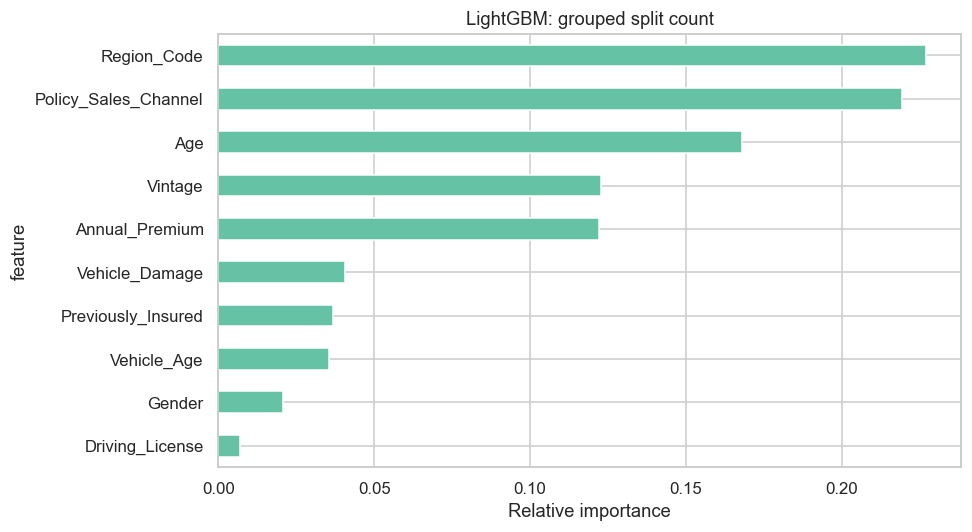

In [21]:
feature_names = final_model.named_steps['preprocess'].get_feature_names_out()
fitted_estimator = final_model.named_steps['model']
if hasattr(fitted_estimator, 'feature_importances_'):
    values = fitted_estimator.feature_importances_.astype(float)
    importance_label = ('split count' if best_name == 'LightGBM' else 'tree importance')
else:
    values = np.abs(fitted_estimator.coef_[0])
    importance_label = 'absolute coefficient (different scaling by feature type)'
importance = pd.DataFrame({'encoded_feature': feature_names, 'importance': values})

def original_feature_name(encoded_name):
    name = encoded_name.split('__', 1)[1]
    for column in CATEGORY_COLUMNS:
        if name.startswith(column + '_'):
            return column
    return name

importance['feature'] = importance['encoded_feature'].map(original_feature_name)
grouped_importance = importance.groupby('feature')['importance'].sum().sort_values(ascending=False)
if grouped_importance.sum() > 0:
    grouped_importance = grouped_importance / grouped_importance.sum()
display(grouped_importance.to_frame('relative_importance'))
fig, ax = plt.subplots(figsize=(9, 5))
grouped_importance.sort_values().plot.barh(ax=ax)
ax.set(title=f'{best_name}: grouped {importance_label}', xlabel='Relative importance')
plt.tight_layout(); plt.show()
importance.sort_values('importance', ascending=False).to_csv(
    OUT_DIR / 'encoded_feature_importance.csv', index=False)
grouped_importance.to_csv(OUT_DIR / 'grouped_feature_importance.csv')

### 7-2. 결론·한계·개선 방향

아래 요약은 실제 실행 결과에서 자동으로 작성한다. 점수를 직접 입력해 결과와 설명이 달라지는 일을 피한다.

In [22]:
final_metrics = metric_values(y_holdout, holdout_probability, selected_threshold)
default_metrics = metric_values(y_holdout, holdout_probability, 0.5)
logistic_cv = comparison.loc['LogisticRegression', 'CV_ROC_AUC']
cv_improvement = selected_cv_mean - logistic_cv
top_features = ', '.join(grouped_importance.head(3).index)
summary = f"""
### 실행 결과 요약

- 선정 모델: **{best_name}**, 전처리 조건: **{selected_spec['name']}**.
- 선정 구성의 3-fold CV ROC-AUC: **{selected_cv_mean:.5f} ± {selected_cv_std:.5f}**.
- 최종 holdout ROC-AUC: **{holdout_auc:.5f}**, AP: **{holdout_ap:.5f}**.
- ROC-AUC 0.85 목표: **{'달성' if holdout_auc >= 0.85 else '미달성'}**.
- 로지스틱 회귀 대비 CV ROC-AUC 차이: **{cv_improvement:+.5f}**;
  0.01 개선 목표: **{'달성' if cv_improvement >= 0.01 else '미달성'}**.
- 기본 임계값 0.50: 정밀도 **{default_metrics['Precision']:.2%}**,
  재현율 **{default_metrics['Recall']:.2%}**, F1 **{default_metrics['F1']:.4f}**.
- 검증셋에서 고정한 임계값 {selected_threshold:.2f}: 정밀도 **{final_metrics['Precision']:.2%}**,
  재현율 **{final_metrics['Recall']:.2%}**, F1 **{final_metrics['F1']:.4f}**.
- 학습 전체 행과 holdout ROC-AUC 격차: **{auc_gap:.5f}**.
- 모델에서 크게 사용한 변수: **{top_features}**. 중요도와 EDA의 관심 비율을 함께 설명한다.

### 도메인 관점의 해석

확률 순위를 활용하면 관심 가능성이 높은 고객부터 안내하는 전략을 검토할 수 있다.
임계값을 낮추면 더 많은 관심 고객을 찾는 대신 관심 없는 고객에게도 안내할 수 있다.
실제 영업 적용에는 연락 비용, 가입 전환율, 고객 동의·선호 정보가 추가로 필요하다.

### 한계와 개선 방향

1. 타깃은 **관심 여부**이며 실제 가입·매출·이익을 측정하지 않는다.
2. 무작위 분할 평가는 비슷한 모집단의 고객에 대한 결과다. 다른 시기·지역에서도 유지되는지는 별도 검증이 필요하다.
3. CV와 검증셋을 여러 후보 선택에 사용하므로 선택 편향이 있다. 최종 holdout을 다시 튜닝에 사용하지 않는다.
4. 모델 중요도는 인과관계가 아니며 상관된 변수 사이에서 중요도가 분산될 수 있다.
5. IQR 밖의 보험료도 정상 고객일 수 있다. 제거 여부는 근거와 비교 결과를 함께 설명한다.
6. 성별·연령 집단에 따라 오류가 다를 수 있으므로 실제 적용 전 집단별 성능과 데이터 대표성을 추가 점검한다.
7. 이번 탐색 범위는 제한되어 있다. 추가 데이터, 별도 검증셋, 수업 범위의 탐색 확대로 개선하되 현재 holdout에 맞춰 조정하지 않는다.
"""
display(Markdown(summary))
(OUT_DIR / 'result_summary.md').write_text(summary, encoding='utf-8')


### 실행 결과 요약

- 선정 모델: **LightGBM**, 전처리 조건: **original**.
- 선정 구성의 3-fold CV ROC-AUC: **0.85669 ± 0.00121**.
- 최종 holdout ROC-AUC: **0.85768**, AP: **0.36953**.
- ROC-AUC 0.85 목표: **달성**.
- 로지스틱 회귀 대비 CV ROC-AUC 차이: **+0.00830**;
  0.01 개선 목표: **미달성**.
- 기본 임계값 0.50: 정밀도 **57.14%**,
  재현율 **0.30%**, F1 **0.0060**.
- 검증셋에서 고정한 임계값 0.25: 정밀도 **33.77%**,
  재현율 **71.11%**, F1 **0.4580**.
- 학습 전체 행과 holdout ROC-AUC 격차: **0.00608**.
- 모델에서 크게 사용한 변수: **Region_Code, Policy_Sales_Channel, Age**. 중요도와 EDA의 관심 비율을 함께 설명한다.

### 도메인 관점의 해석

확률 순위를 활용하면 관심 가능성이 높은 고객부터 안내하는 전략을 검토할 수 있다.
임계값을 낮추면 더 많은 관심 고객을 찾는 대신 관심 없는 고객에게도 안내할 수 있다.
실제 영업 적용에는 연락 비용, 가입 전환율, 고객 동의·선호 정보가 추가로 필요하다.

### 한계와 개선 방향

1. 타깃은 **관심 여부**이며 실제 가입·매출·이익을 측정하지 않는다.
2. 무작위 분할 평가는 비슷한 모집단의 고객에 대한 결과다. 다른 시기·지역에서도 유지되는지는 별도 검증이 필요하다.
3. CV와 검증셋을 여러 후보 선택에 사용하므로 선택 편향이 있다. 최종 holdout을 다시 튜닝에 사용하지 않는다.
4. 모델 중요도는 인과관계가 아니며 상관된 변수 사이에서 중요도가 분산될 수 있다.
5. IQR 밖의 보험료도 정상 고객일 수 있다. 제거 여부는 근거와 비교 결과를 함께 설명한다.
6. 성별·연령 집단에 따라 오류가 다를 수 있으므로 실제 적용 전 집단별 성능과 데이터 대표성을 추가 점검한다.
7. 이번 탐색 범위는 제한되어 있다. 추가 데이터, 별도 검증셋, 수업 범위의 탐색 확대로 개선하되 현재 holdout에 맞춰 조정하지 않는다.


1125

## 8. 전체 학습 데이터로 재학습하고 제출 파일 생성
독립 성능 평가는 끝났다. 제출용 모델은 선택한 설정을 유지하고 `train.csv` 전체로 다시 학습한다.
이 모델의 새로운 독립 평가 점수는 알 수 없으며, 앞의 holdout 점수는 **60% 학습 모델**의 점수이다.
IQR 제거가 선택됐으면 전체 학습 데이터에서만 경계를 새로 계산한다.
`test.csv`의 127,037개 고객 모두에 대해 관심 **확률**을 저장한다. 임계값으로 만든 0/1은 제출하지 않는다.
Kaggle 계정에 자동 업로드하지 않고 로컬 파일만 생성한다.

In [23]:
kaggle_test = pd.read_csv(DATA_DIR / 'test.csv')
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')
assert TARGET not in kaggle_test.columns
assert kaggle_test[ID].is_unique
assert not set(train[ID]).intersection(set(kaggle_test[ID]))
assert sample_submission.columns.tolist() == [ID, TARGET]
assert sample_submission[ID].is_unique
assert set(sample_submission[ID]) == set(kaggle_test[ID])

all_features = train.drop(columns=[ID, TARGET])
all_target = train[TARGET]
test_features = kaggle_test.drop(columns=ID)
assert all_features.columns.tolist() == test_features.columns.tolist()

if selected_spec['remove_iqr']:
    full_lower, full_upper = premium_iqr_bounds(all_features)
    full_keep = all_features['Annual_Premium'].between(full_lower, full_upper)
else:
    full_keep = pd.Series(True, index=all_features.index)

full_train_prepared = prepare_features(all_features.loc[full_keep], selected_spec['engineered'])
test_prepared = prepare_features(test_features, selected_spec['engineered'])
submission_model = make_pipeline(best_name, best_estimator, full_train_prepared)
submission_model.fit(full_train_prepared, all_target.loc[full_keep])
test_probability = submission_model.predict_proba(test_prepared)[:, 1]

# ID로 정렬을 맞춰 sample_submission의 순서를 그대로 지킨다.
probability_by_id = pd.Series(test_probability, index=kaggle_test[ID])
submission = sample_submission.copy()
submission[TARGET] = submission[ID].map(probability_by_id)
assert len(submission) == len(kaggle_test)
assert submission[TARGET].notna().all()
assert np.isfinite(submission[TARGET]).all()
assert submission[TARGET].between(0, 1).all()
assert submission[ID].equals(sample_submission[ID])
submission_path = OUT_DIR / 'submission_test2.csv'
submission.to_csv(submission_path, index=False)
display(submission.head())
print('저장:', submission_path, '| 행 수:', len(submission))
print('확률 범위:', submission[TARGET].min(), '~', submission[TARGET].max())

,id,Response
0,381110,0.000549
1,381111,0.320713
2,381112,0.299828
3,381113,0.007347
4,381114,0.000423


저장: /Users/yoon/Documents/Machine_Learning/project/test2_outputs/submission_test2.csv | 행 수: 127037
확률 범위: 0.0002825362401479352 ~ 0.6613298116883273


## 9. 재현 정보와 15분 발표 정리
CSV의 SHA-256 해시와 패키지 버전을 기록해 동일한 원본·환경인지 비교할 수 있게 한다.
난수 시드를 고정해도 운영체제·라이브러리·병렬 연산 차이로 아주 작은 수치 차이가 생길 수 있다.

|발표 순서|시간|핵심 내용|
|---|---:|---|
|문제 정의·데이터|2분|관심 여부 예측, 0/1 정의, 활용 목적, 불균형|
|EDA|3분|타깃 분포, 기존 보험·손상과 관심 비율, 상관관계|
|전처리|2분|ID 제외, 코드 인코딩, 이상치 비교, 누수 방지|
|모델 비교·튜닝|3분|기준 모델, 동일 CV, 튜닝 이유와 실험 로그|
|최종 평가|3분|ROC-AUC/AP, 오차행렬, 임계값의 trade-off|
|결론·한계|2분|중요 변수, 관심과 가입의 차이, 향후 검증|

**예상 질문**
- 왜 정확도만 보지 않았나? → 전부 0으로 예측해도 정확도가 높지만 관심 고객을 찾지 못한다.
- 이상치는 왜 무조건 제거하지 않았나? → 큰 보험료가 정상 고객일 수 있어 같은 모델의 유지/제거 실험으로 판단했다.
- 테스트 데이터가 학습에 들어가지 않았나? → holdout은 설정 고정 후 평가했고, 제출용 test는 마지막 predict에만 사용했다.
- 왜 0.5가 아닌 임계값도 쓰나? → 검증 F1 기준으로 Precision/Recall 균형을 비교했다. 수익 최적값은 아니다.
- 왜 이 모델이 최고인가? → 같은 데이터와 CV, 지정한 탐색 범위에서 선택했으며 모든 가능한 모델 중 최고라는 주장은 아니다.

PDF의 단계별 체크리스트는 이 노트북의 1~9절에 대응한다. 보고서에 옮길 때는 `result_summary.md`와 실험 표를 참고한다.

In [24]:
input_hashes = {}
for filename in ['train.csv', 'test.csv', 'sample_submission.csv', 'Guidline.pdf']:
    path = DATA_DIR / filename
    if path.exists():
        input_hashes[filename] = hashlib.sha256(path.read_bytes()).hexdigest()
reproduction = {
    'python': sys.version, 'packages': versions, 'seed': SEED,
    'input_sha256': input_hashes,
    'split_rows': {'fit': len(X_fit), 'validation': len(X_valid), 'holdout': len(X_holdout)},
    'submission_fit_rows': int(full_keep.sum()),
    'submission_rows': len(submission),
}
(OUT_DIR / 'reproducibility.json').write_text(
    json.dumps(reproduction, ensure_ascii=False, indent=2), encoding='utf-8')
print('전체 실행 완료. 주요 파일:')
for filename in ['model_comparison.csv', 'model_cv_folds.csv', 'grid_search_results.csv',
                 'preprocessing_experiments.csv', 'validation_thresholds.csv',
                 'evaluation_metrics.csv', 'selected_config.json',
                 'result_summary.md', 'submission_test2.csv', 'reproducibility.json']:
    print('-', OUT_DIR / filename)

전체 실행 완료. 주요 파일:
- /Users/yoon/Documents/Machine_Learning/project/test2_outputs/model_comparison.csv
- /Users/yoon/Documents/Machine_Learning/project/test2_outputs/model_cv_folds.csv
- /Users/yoon/Documents/Machine_Learning/project/test2_outputs/grid_search_results.csv
- /Users/yoon/Documents/Machine_Learning/project/test2_outputs/preprocessing_experiments.csv
- /Users/yoon/Documents/Machine_Learning/project/test2_outputs/validation_thresholds.csv
- /Users/yoon/Documents/Machine_Learning/project/test2_outputs/evaluation_metrics.csv
- /Users/yoon/Documents/Machine_Learning/project/test2_outputs/selected_config.json
- /Users/yoon/Documents/Machine_Learning/project/test2_outputs/result_summary.md
- /Users/yoon/Documents/Machine_Learning/project/test2_outputs/submission_test2.csv
- /Users/yoon/Documents/Machine_Learning/project/test2_outputs/reproducibility.json
